# 01 · Carga y limpieza del corpus de reseñas de Amazon

**Proyecto:** Clasificación automática de reseñas de Amazon (Hogar y Cocina) — Inteligencia de Datos, Universidad Iberoamericana León.

Este notebook corresponde a la **sección 2 del protocolo** (*Recolección y selección de datos*):

1. Leer las 15,000 reseñas (un archivo JSON por reseña, en las carpetas `negative/`, `neutral/` y `positive/`).
2. Seleccionar las variables relevantes.
3. Eliminar registros vacíos, duplicados y reseñas demasiado cortas.
4. Analizar la distribución inicial de las clases (estrellas / polaridad) y la longitud de las reseñas.

**Resultado esperado:** `datos/resenas_limpias.csv`, un conjunto de datos limpio y listo para el etiquetado.

In [1]:
# Librerías
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Funciones compartidas del proyecto (rutas, carga del corpus, etc.)
import utils
from utils import DATOS, RESULTADOS, COLUMNAS_CONSERVAR, ARCHIVO_LIMPIO

# Carpeta donde se guardan las gráficas y tablas de exploración
SALIDA = RESULTADOS / "exploracion"
SALIDA.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

## 1. Leer los archivos JSON

Cada archivo JSON es una reseña con los campos `id, category, polarity, rating, title, text, asin, parent_asin, user_id, timestamp, helpful_vote, verified_purchase, product_metadata`.
La función `utils.cargar_corpus()` recorre las tres carpetas y arma un solo `DataFrame`. Si la carpeta descomprimida no existiera, lee directamente del `.zip` original **sin modificarlo**.

In [2]:
df_crudo = utils.cargar_corpus()
print("Dimensiones del corpus crudo:", df_crudo.shape)
print("Columnas:", list(df_crudo.columns))
df_crudo[["id", "carpeta", "polarity", "rating", "text"]].head()

Dimensiones del corpus crudo: (15000, 13)
Columnas: ['id', 'category', 'polarity', 'rating', 'title', 'text', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase', 'carpeta']


,id,carpeta,polarity,rating,text
0,AE25NQAZI3725GZIL5FS52ZIKWKQ_B00H4P4ZBO_1453523941000,negative,negative,2.0,Will not use this vendor again.. Disappointed. Very expensive for such a small selection of shells and most not big...
1,AE25NQAZI3725GZIL5FS52ZIKWKQ_B07JGKK5M5_1562427159928,negative,negative,1.0,Chewed up the edges of my new area rug. Chewed up the edges of my new area rug. Way too heavy and having to stand it...
2,AE25NQAZI3725GZIL5FS52ZIKWKQ_B0BZQZXHWP_1510599919790,negative,negative,1.0,Too heavy for me to install. Soooo heavy i can not install it. Excellent quality but very heavy
3,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B004OF968O_1493389988000,negative,negative,1.0,"Not for me..... I was not expecting much, but for me, these bags are a joke. I can't believe so many are still avai..."
4,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B00P9UC004_1521055721867,negative,negative,1.0,"Very small size. These are so small everything falls off. Too small for baseball caps, they just fall off. The pic..."


### Verificaciones de consistencia

Antes de limpiar, comprobamos que la carpeta coincide con la polaridad y que la polaridad corresponde a las estrellas
(negative = 1-2, neutral = 3, positive = 4-5). También confirmamos que toda la categoría es *Home_and_Kitchen*.

In [3]:
print("¿Carpeta == polarity en todas las reseñas?", (df_crudo["carpeta"] == df_crudo["polarity"]).all())
print("\nCategorías presentes:")
print(df_crudo["category"].value_counts())
print("\nEstrellas por polaridad:")
pd.crosstab(df_crudo["rating"], df_crudo["polarity"])

¿Carpeta == polarity en todas las reseñas? True

Categorías presentes:
category
Home_and_Kitchen    15000
Name: count, dtype: int64

Estrellas por polaridad:


polarity,negative,neutral,positive
rating,,,
1.0,3035,0,0
2.0,1965,0,0
3.0,0,5000,0
4.0,0,0,1007
5.0,0,0,3993


## 2. Seleccionar variables relevantes

Conservamos `text, rating, polarity, category, asin, verified_purchase` y además el `id` (identificador único que nos permite
unir resultados entre notebooks y con la muestra de validación manual). El campo `text` **ya incluye el título** al inicio,
por lo que no hace falta concatenarlo.

> `rating` y `polarity` se conservan **solo para análisis**; nunca se usarán como característica de los modelos.

In [4]:
df = df_crudo[COLUMNAS_CONSERVAR].copy()
df.dtypes

id                       str
text                     str
rating               float64
polarity                 str
category                 str
asin                     str
verified_purchase       bool
dtype: object

## 3. Limpieza de registros

Pasos (registrando cuántas reseñas se eliminan en cada uno):

1. **Registros vacíos:** `text` nulo o formado solo por espacios.
2. **Duplicados:** el mismo texto repetido (comparando sin mayúsculas ni espacios extra). Se conserva la primera aparición.
3. **Reseñas muy cortas:** de 3 palabras o menos (por ejemplo, *"Great. Love it"*), porque no aportan información suficiente para distinguir entre Producto, Envío y Sentimiento.

In [5]:
bitacora = [("Corpus inicial", len(df))]

# 1) Registros vacíos
df["text"] = df["text"].fillna("").astype(str)
vacios = df["text"].str.strip() == ""
df = df[~vacios]
bitacora.append(("Sin registros vacíos", len(df)))

# 2) Duplicados: normalizamos (minúsculas y espacios) solo para comparar
clave = df["text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
duplicados = clave.duplicated(keep="first")
print("Textos duplicados encontrados:", int(duplicados.sum()))
# ¿Algún duplicado aparece con polaridades distintas? (solo informativo)
grupos = df.assign(clave=clave).groupby("clave")["polarity"].nunique()
print("Textos repetidos con polaridad distinta:", int((grupos > 1).sum()))
df = df[~duplicados]
bitacora.append(("Sin duplicados", len(df)))

# 3) Reseñas de 3 palabras o menos
df["n_palabras"] = df["text"].str.split().str.len()
cortas = df["n_palabras"] <= 3
print("Reseñas de 3 palabras o menos:", int(cortas.sum()))
print(df.loc[cortas, "text"].head(8).tolist())
df = df[~cortas].reset_index(drop=True)
bitacora.append(("Sin reseñas de <= 3 palabras", len(df)))

bitacora = pd.DataFrame(bitacora, columns=["paso", "reseñas_restantes"])
bitacora["eliminadas_en_el_paso"] = (-bitacora["reseñas_restantes"].diff()).fillna(0).astype(int)
bitacora.to_csv(SALIDA / "bitacora_limpieza.csv", index=False, encoding="utf-8-sig")
bitacora

Textos duplicados encontrados: 51
Textos repetidos con polaridad distinta: 3


Reseñas de 3 palabras o menos: 123
['Good. Good', 'Two Stars. plastic', 'One Star. Junk', 'Garbage. Garbage!', 'Terrible. These suck', 'Lights. Junk', 'Wine stopper. Junk', 'One Star. Awful']


,paso,reseñas_restantes,eliminadas_en_el_paso
0,Corpus inicial,15000,0
1,Sin registros vacíos,15000,0
2,Sin duplicados,14949,51
3,Sin reseñas de <= 3 palabras,14826,123


## 4. Distribución inicial de las clases

El corpus viene **balanceado por polaridad** (5,000 reseñas por carpeta). Después de la limpieza revisamos cómo quedó la
distribución por polaridad y por estrellas. Recordemos que estas no son las etiquetas del proyecto: el objetivo es clasificar
**el tipo de reseña** (Producto, Envío o Sentimiento), justamente porque las estrellas son un criterio vago.

Distribución por polaridad:
 polarity
negative    4947
neutral     4952
positive    4927
Name: count, dtype: int64 

Distribución por estrellas:
 rating
1.0    2997
2.0    1950
3.0    4952
4.0     993
5.0    3934
Name: count, dtype: int64


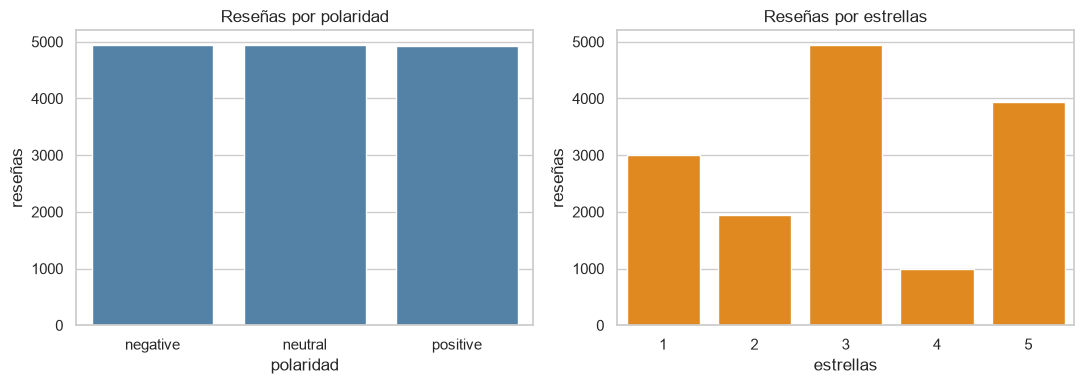

In [6]:
dist_polaridad = df["polarity"].value_counts().reindex(["negative", "neutral", "positive"])
dist_estrellas = df["rating"].value_counts().sort_index()
print("Distribución por polaridad:\n", dist_polaridad, "\n")
print("Distribución por estrellas:\n", dist_estrellas)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=dist_polaridad.index, y=dist_polaridad.values, ax=ejes[0], color="steelblue")
ejes[0].set_title("Reseñas por polaridad"); ejes[0].set_xlabel("polaridad"); ejes[0].set_ylabel("reseñas")
sns.barplot(x=dist_estrellas.index.astype(int), y=dist_estrellas.values, ax=ejes[1], color="darkorange")
ejes[1].set_title("Reseñas por estrellas"); ejes[1].set_xlabel("estrellas"); ejes[1].set_ylabel("reseñas")
fig.tight_layout()
fig.savefig(SALIDA / "distribucion_inicial.png", dpi=120)
plt.show()

## 5. Longitud de las reseñas

La longitud (en palabras) nos ayuda a entender el corpus y a elegir parámetros del preprocesamiento. Las reseñas largas suelen
mezclar varios temas (por ejemplo, un elogio general y un defecto concreto), lo que hace más difícil asignar una sola etiqueta.

,count,mean,std,min,25%,50%,75%,max
polarity,,,,,,,,
negative,4947.0,65.2,88.1,4.0,19.0,38.0,75.0,1336.0
neutral,4952.0,87.0,112.4,4.0,27.0,53.0,102.0,1797.0
positive,4927.0,59.3,63.6,4.0,18.0,39.0,76.0,715.0
total,14826.0,70.5,91.1,4.0,20.0,43.0,84.0,1797.0


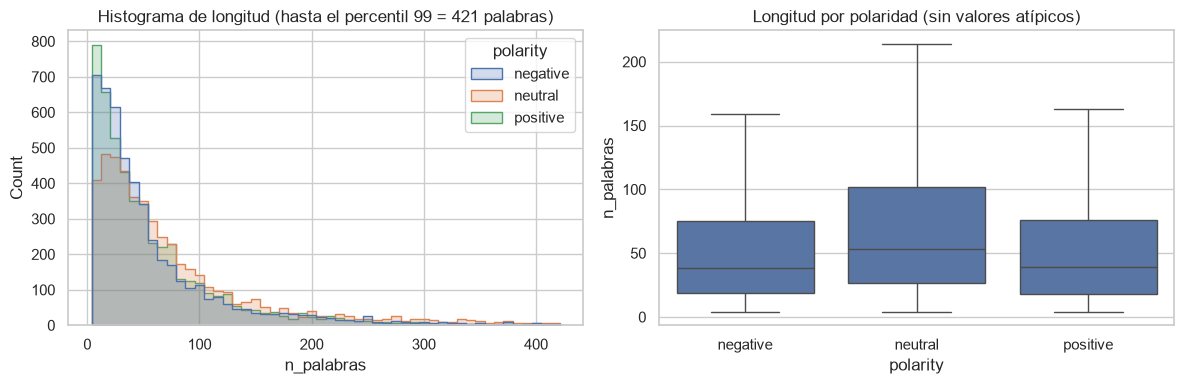

In [7]:
resumen_longitud = df.groupby("polarity")["n_palabras"].describe().round(1)
resumen_longitud.loc["total"] = df["n_palabras"].describe().round(1)
resumen_longitud.to_csv(SALIDA / "longitud_resenas.csv", encoding="utf-8-sig")
display(resumen_longitud)

limite = df["n_palabras"].quantile(0.99)  # recortamos el 1 % más largo solo para que la gráfica sea legible
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df[df["n_palabras"] <= limite], x="n_palabras", hue="polarity", bins=50,
             element="step", ax=ejes[0])
ejes[0].set_title(f"Histograma de longitud (hasta el percentil 99 = {limite:.0f} palabras)")
sns.boxplot(data=df, x="polarity", y="n_palabras", order=["negative", "neutral", "positive"],
            showfliers=False, ax=ejes[1])
ejes[1].set_title("Longitud por polaridad (sin valores atípicos)")
fig.tight_layout()
fig.savefig(SALIDA / "longitud_resenas.png", dpi=120)
plt.show()

## 6. Guardar el conjunto limpio

In [8]:
df.to_csv(ARCHIVO_LIMPIO, index=False, encoding="utf-8-sig")
print(f"Guardado: {ARCHIVO_LIMPIO.relative_to(utils.BASE)}  ->  {df.shape[0]} reseñas, {df.shape[1]} columnas")

Guardado: datos\resenas_limpias.csv  ->  14826 reseñas, 8 columnas


### Conclusión

El corpus quedó sin registros vacíos, sin textos duplicados y sin reseñas demasiado cortas (ver `bitacora_limpieza.csv`).
La distribución por polaridad sigue prácticamente balanceada. El siguiente paso (notebook 02) es generar las etiquetas
**Producto / Envío / Sentimiento**.